In [80]:
import matplotlib.pyplot as plt
import numpy as np
import math
from IPython.display import Audio
import scipy

# Resampling

Objectif : ...

todo:
- cell code 1: load play, resample, play drumloop, swap with corrupted drumloop, observe pb
- cell code 2: to fft, filter, back to time: resample works
- cell code 3: numpy resample does it for you

## Resample

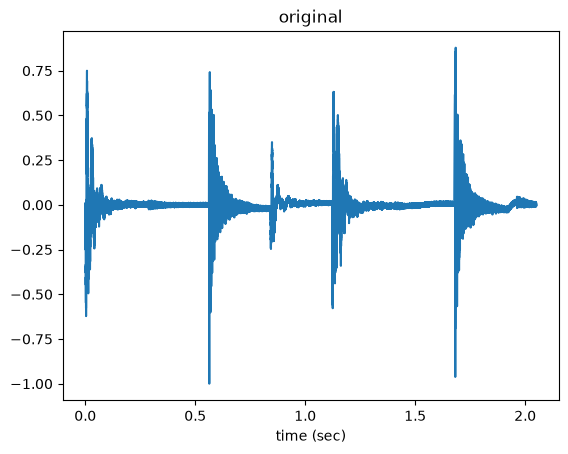

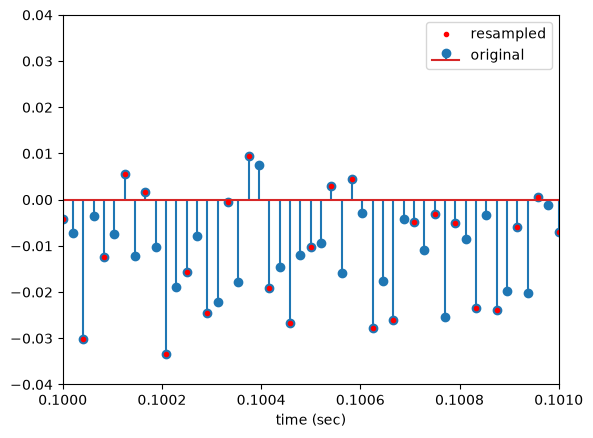

In [ ]:
# init locals
downsampling_factor = 2

# load audio 
fs_in, audio_in = scipy.io.wavfile.read('../assets/drums.wav')
# fs_in, audio_in = scipy.io.wavfile.read('../assets/drums_corrupted.wav')

# normalise
audio_in = audio_in / np.max(np.abs(audio_in))

# resample
fs_out = fs_in/downsampling_factor
audio_out = audio_in[::downsampling_factor]

# plot
t_in = np.arange(len(audio_in)) / fs_in
plt.plot(t_in, audio_in)
plt.xlabel('time (sec)'); plt.title('original'); plt.show()

# plot
t_out = np.arange(len(audio_out)) / fs_out
plt.stem(t_in, audio_in, 'o', label='original')
plt.plot(t_out, audio_out, 'or', markersize = 3, label='resampled')
plt.xlim([0.1, 0.101])
o = 0.04; plt.ylim([-o, o])
plt.xlabel('time (sec)'); plt.legend(); plt.show()

# play
display(Audio(audio_in, rate=fs_in))
display(Audio(audio_out, rate=fs_out))


## Investigate

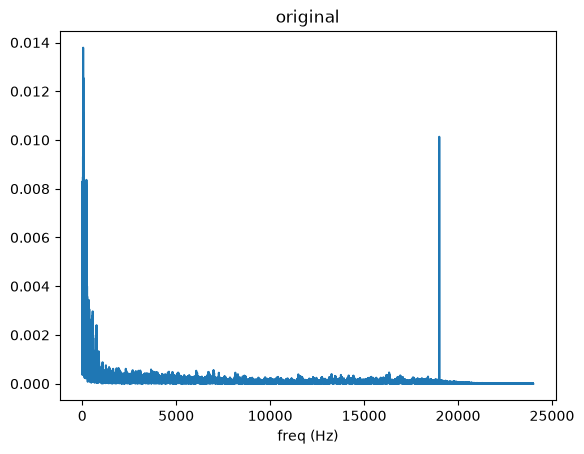

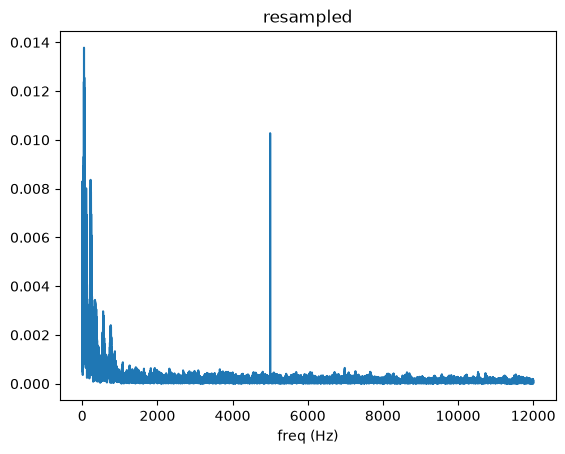

In [89]:

# fft original
n = len(audio_in)
X = np.fft.rfft(audio_in, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs_in)

# plot
plt.plot(f, np.abs(X))
plt.xlabel('freq (Hz)')
plt.title('original')
plt.show()

# fft resampled
n = len(audio_out)
X = np.fft.rfft(audio_out, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs_out)

# plot
plt.plot(f, np.abs(X))
plt.xlabel('freq (Hz)')
plt.title('resampled')
plt.show()


## Pre-filter for anti-aliasing

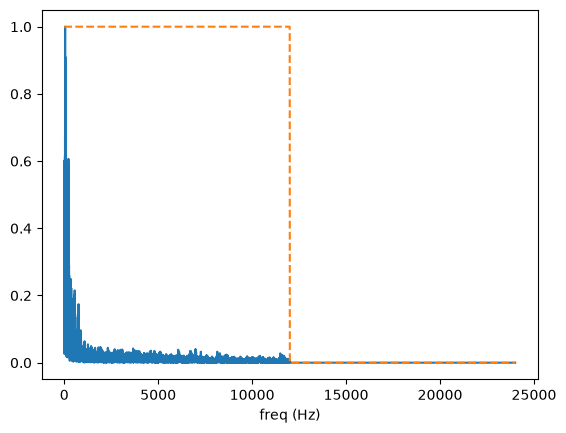

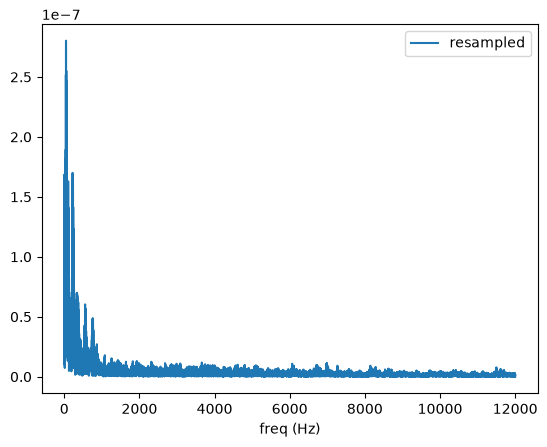

24000.0


In [ ]:
# fft
n = len(audio_in)
X = np.fft.rfft(audio_in, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs_in)

# filter
W = np.ones(len(X))
W[f > fs_out/2] = 0
X *= W
audio_in_filtered = np.fft.irfft(X, len(audio_in))

# plot
plt.plot(f, np.abs(X) / np.max(np.abs(X)), label = 'original filtered')
plt.plot(f, W, '--', label = 'filter')
plt.xlabel('freq (Hz)')
plt.show()

# resample
audio_out = audio_in_filtered[::downsampling_factor]

# fft
n = len(audio_out)
X = np.fft.rfft(audio_out, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs_out)

# plot
plt.plot(f, np.abs(X), label = 'resampled')
plt.xlabel('freq (Hz)')
plt.legend()
plt.show()

# play
display(Audio(audio_out, rate=fs_out))


## Scipy resample

In [ ]:
# resample with auto anti-aliasing filter (using fft and trimming / zero-padding)
n = int(len(audio_in) / (fs_in/fs_out))
audio_out = scipy.signal.resample(audio_in, n)

# play
display(Audio(audio_out, rate=fs_out))